# Arabica–robusta: reflectance training samples (raw scans → patch spectra)

The arabica extraction (`arabica_reflectance_samples.ipynb`) run on the arabica–robusta scans in
`RIYAN HDD/arabica+robusta/`. Identical reader, dark-signal subtraction, white reference, automatic dish detection,
masks and 12 × 12 px patches; only the labels and the checks differ.

**Dish order from the white strip** (from the sample list; AR[a:r] = arabica % : robusta %):

| Scan set | Files | Dishes, strip → bottom |
|---|---|---|
| session 1 — 4 Sep ~12:00 | `stir1/2/3 … T115614 / T120652 / T121548` | J, K, L, AR 50-50, AR 60-40, AR 70-30 |
| session 2 — 4 Sep ~13:30 | `stir1/2/3 … T132731 / T133854 / T134533` | AR 80-20, AR 90-10, AR 50-50, AR 100 |
| session 3 — 7 Sep | `batch1stir1/2/3 … 2026-09-07` | AR 55-45, 65-35, 75-25, 85-15, 95-05 — **files not on the HDD yet**; picked up automatically once copied into the folder |

J, K and L are test samples of unknown composition: extracted and saved with role `unknown`, never used for training.
**AR 100 is taken as pure arabica** (0 % robusta); section 10 checks this against the pure arabica and pure robusta
dishes of 1 Sep. The regression target for this mixture is `robusta_pct` (0–50 %).

**Outputs:** `arabica_robusta_out/`.

## 1. Configuration

In [1]:
import os, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
from scipy import ndimage, signal
import cv2

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "white"})

# ------------------------------------ EDIT ------------------------------------
BASE      = Path(os.environ.get("COFFEE_DATA", "."))
DATA_DIR  = Path(os.environ.get("COFFEE_RAW", "/run/media/riyanvarghese/RIYAN HDD")) / "arabica+robusta"  # the raw arabica-robusta scans
PANEL_TXT = BASE / "SRT-MS-050__1_.txt"
OUT       = BASE / "arabica_robusta_out"
S1_CSV    = BASE / "samples_out" / "training_samples.csv"               # AB100 + RB100 from 1 Sep (checks only)
CHECK_RAD = BASE / "stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32.img"  # robusta, same day

# Dishes in order FROM THE WHITE STRIP downwards (user's sample list). AR[a:r] = arabica % : robusta %.
# J, K, L are test samples of unknown composition: extracted, never used for training.
PLATES_A = ["J", "K", "L", "AR[50:50]", "AR[60:40]", "AR[70:30]"]              # 4 Sep ~12:00
PLATES_B = ["AR[80:20]", "AR[90:10]", "AR[50:50]", "AR100"]                    # 4 Sep ~13:30
PLATES_C = ["AR[55:45]", "AR[65:35]", "AR[75:25]", "AR[85:15]", "AR[95:5]"]    # 7 Sep (files not copied yet)
DAY_RULES = ([(t, 1, PLATES_A) for t in ("T115614", "T120652", "T121548")]
             + [(t, 2, PLATES_B) for t in ("T132731", "T133854", "T134533")]
             + [("2026-09-07", 3, PLATES_C)])

# Keep these identical to the robusta extraction, or the samples will not be comparable.
ROUND_WL   = 0      # decimals on the wavelength column names: 0 -> 952, 958, 963 ...
PATCH      = 12     # patch side in pixels
STRIDE     = 12     # == PATCH means non-overlapping
MIN_VALID  = 0.92   # a patch is kept only if this fraction of its pixels are inside the mask
MAX_PER_PLATE = 150 # cap; patches beyond this are randomly subsampled
ERODE_PX   = 4      # trimmed inward from the dish shape
MM_PER_PX  = 0.73   # header nominal, used only to report patch size in mm
SEED = 0

# automatic shapes: dish shape = detected rim circle shrunk by this many pixels,
# white rectangle = detected bright strip shrunk by this many rows top and bottom
DISH_INSET_PX  = 6
STRIP_INSET_PX = 8
EDIT_BY_HAND   = False   # True opens the OpenCV drawing window (section 4b) to adjust shapes
# -------------------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
ROI_FILE = OUT / "rois.json"
RNG = np.random.default_rng(SEED)
print("data dir exists:", DATA_DIR.exists(), "| output:", OUT)

data dir exists: True | output: /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_robusta_out


## 2. Reading the raw HySpex scans

Each `.hyspex` file is a 2.6 MB binary header followed by the image (unsigned 16-bit counts, band-interleaved
by line). The header holds, in order: the 288 band wavelengths, a spectral response vector, a 288 × 384
response matrix, and the **background**: the mean of the 200 dark frames the camera records before each
scan, per band and across-track column. The reader finds the wavelength list in the header and reads the
background that follows, then subtracts it from every frame it returns. Saturated pixels (65535) become
missing values.

In [2]:
ENVI_DTYPES = {1:"u1", 2:"i2", 3:"i4", 4:"f4", 5:"f8", 12:"u2", 13:"u4"}

def parse_envi_header(p):
    txt = Path(p).read_text(errors="ignore").replace("\r", "")
    body = txt.split("\n", 1)[1] if "\n" in txt else ""
    out, pos = {}, 0
    pat = re.compile(r"^\s*([\w\s]+?)\s*=\s*(\{.*?\}|[^\n]*)", re.S | re.M)
    while pos < len(body):
        m = pat.search(body, pos)
        if not m: break
        k, v = m.group(1).strip().lower(), m.group(2).strip()
        if v.startswith("{") and not v.endswith("}"):
            e = body.find("}", m.end(2)); v = body[m.start(2):e+1]; pos = e + 1
        else: pos = m.end(2)
        out[k] = v
    for k in ["samples","lines","bands","header offset","data type","byte order"]:
        if k in out: out[k] = int(float(out[k]))
    if "data ignore value" in out: out["data ignore value"] = float(out["data ignore value"])
    if "wavelength" in out:
        out["wavelength"] = np.array([float(x) for x in
            out["wavelength"].strip("{}").replace("\n"," ").split(",") if x.strip()])
    out["interleave"] = out.get("interleave","bsq").strip().lower()
    return out


def hyspex_background(path, header_bytes, wl, S):
    # Locate the wavelength list (packed float64, not 8-byte aligned) in the binary header.
    # Layout after it: response vector (B), response matrix (B x S), background (B x S).
    raw = Path(path).open("rb").read(header_bytes)
    B = wl.size
    for off in range(0, min(len(raw) - 16, 20000)):
        a, b = np.frombuffer(raw, "<f8", count=2, offset=off)
        if abs(a - wl[0]) < 1e-3 and abs(b - wl[1]) < 1e-3:
            break
    else:
        raise ValueError(f"{Path(path).name}: wavelength table not found in the header")
    hw = np.frombuffer(raw, "<f8", count=B, offset=off)
    assert np.allclose(hw, wl, atol=1e-3), "header wavelengths do not match the .hdr"
    bg_off = off + 2 * B * 8 + B * S * 8
    bg = np.frombuffer(raw, "<f8", count=B * S, offset=bg_off).reshape(B, S)
    assert 100 < np.median(bg) < 60000, f"implausible background level {np.median(bg):.0f}"
    return bg.T.astype(np.float32), bg_off          # (columns, bands)


class Cube:
    def __init__(self, hdr):
        self.hdr_path = Path(hdr); self.h = parse_envi_header(hdr)
        stem = self.hdr_path.with_suffix("")
        self.path = next((c for e in (".hyspex", ".img", ".raw", ".dat", ".bin", "")
                          if (c := stem.with_suffix(e)).exists() and c != self.hdr_path), None)
        if self.path is None: raise FileNotFoundError(f"no data file beside {self.hdr_path.name}")
        L, S, B = self.h["lines"], self.h["samples"], self.h["bands"]
        dtc = ENVI_DTYPES[self.h["data type"]]
        nb = L*S*B*np.dtype(dtc).itemsize; fs = self.path.stat().st_size
        dec = self.h.get("header offset", 0)
        if fs == dec + nb: off, why = dec, "declared offset matches"
        elif fs == nb:     off, why = 0, "no offset"
        else: raise ValueError(f"{self.path.name}: size {fs} vs {nb}+{dec}; file may be truncated")
        self.offset, self.offset_reason = off, why
        dt = np.dtype(dtc).newbyteorder("<" if self.h.get("byte order",0)==0 else ">")
        shp = {"bil":(L,B,S),"bsq":(B,L,S),"bip":(L,S,B)}[self.h["interleave"]]
        mm = np.memmap(self.path, dtype=dt, mode="r", offset=off, shape=shp)
        self.arr = {"bil":mm.transpose(0,2,1),"bsq":mm.transpose(1,2,0),"bip":mm}[self.h["interleave"]]
        self.wl = self.h["wavelength"]; self.ignore = self.h.get("data ignore value", None)
        self.is_raw = np.dtype(dtc).kind == "u"; self._br = {}
        self.bg, self.bg_offset = (hyspex_background(self.path, off, self.wl, S) if self.is_raw
                                   else (np.zeros((S, B), np.float32), None))

    @property
    def shape(self): return self.arr.shape

    def region(self, r0, r1, c0=0, c1=None):
        # dark-subtracted signal, (rows, columns, bands)
        c1 = self.shape[1] if c1 is None else c1
        b = np.array(self.arr[r0:r1, c0:c1, :], dtype=np.float32)
        if self.ignore is not None: b[b == self.ignore] = np.nan
        return b - self.bg[None, c0:c1, :]

    def brightness(self, step=1, lo=1500, hi=1700):
        # mean of 8 bands near 1500-1700 nm, background removed (cached: it is used several times)
        ck = (step, lo, hi)
        if ck in self._br: return self._br[ck]
        idx = [i for i, w in enumerate(self.wl) if lo <= w <= hi][:8]
        s = np.array(self.arr[::step, ::step, :][:, :, idx], dtype=np.float32)
        if self.ignore is not None: s[s == self.ignore] = np.nan
        self._br[ck] = np.nanmean(s - self.bg[None, ::step, idx], axis=2)
        return self._br[ck]


def load_white_cert(txt_path, wl):
    rows = []
    for line in Path(txt_path).read_text(errors="ignore").replace("\r","").split("\n"):
        p = line.strip().split("\t")
        if len(p) >= 2:
            try: rows.append([float(x) for x in p[:5]])
            except ValueError: continue
    a = np.array(rows)
    return np.interp(wl, a[:,0], a[:,1]), (wl < a[0,0]) | (wl > a[-1,0])


def capture_of(stem):
    m = re.search(r"stir\s*(\d+)", stem, re.I)       # stir1 / batch2stir1 -> 1
    return int(m.group(1)) if m else None

CUBES, INFO = {}, {}
for h in sorted(DATA_DIR.glob("*.hdr")):
    c = Cube(h); CUBES[h.stem] = c
    day, plates = next(((d, pl) for s, d, pl in DAY_RULES if s in h.stem), (None, []))
    INFO[h.stem] = dict(day=day, capture=capture_of(h.stem), plates=plates)
    print(f"  {h.stem}\n     {c.shape[0]}x{c.shape[1]}x{c.shape[2]} | {c.offset_reason} | "
          f"background {np.median(c.bg):.0f} counts (header byte {c.bg_offset}) | "
          f"session {day}, stir {INFO[h.stem]['capture']}, {len(plates)} dishes")
assert all(v["day"] is not None for v in INFO.values()), "a scan matched no DAY_RULES entry"

k0 = list(CUBES)[0]
WL = CUBES[k0].wl.copy()
R_WHITE, OUTSIDE = load_white_cert(PANEL_TXT, WL)
WL_R = np.round(WL, ROUND_WL)
if ROUND_WL == 0: WL_R = WL_R.astype(int)
assert len(set(WL_R.tolist())) == WL.size
print(f"\n{WL.size} bands {WL[0]:.1f}-{WL[-1]:.1f} nm | white certificate {R_WHITE[0]:.4f} -> {R_WHITE[-1]:.4f}")

  batch1stir1_SWIR_384_SN3189_9000us_2026-09-07T143543_raw
     1750x384x288 | declared offset matches | background 9749 counts (header byte 891525) | session 3, stir 1, 5 dishes


  batch1stir2_SWIR_384_SN3189_9000us_2026-09-07T144314_raw
     1750x384x288 | declared offset matches | background 9915 counts (header byte 891525) | session 3, stir 2, 5 dishes
  batch1stir3_SWIR_384_SN3189_9000us_2026-09-07T145021_raw
     1750x384x288 | declared offset matches | background 10076 counts (header byte 891525) | session 3, stir 3, 5 dishes


  stir1_SWIR_384_SN3189_9000us_2026-09-04T115614_raw
     2000x384x288 | declared offset matches | background 9873 counts (header byte 891525) | session 1, stir 1, 6 dishes


  stir1_SWIR_384_SN3189_9000us_2026-09-04T132731_raw
     1499x384x288 | declared offset matches | background 10390 counts (header byte 891525) | session 2, stir 1, 4 dishes
  stir2_SWIR_384_SN3189_9000us_2026-09-04T120652_raw
     2000x384x288 | declared offset matches | background 10021 counts (header byte 891525) | session 1, stir 2, 6 dishes


  stir2_SWIR_384_SN3189_9000us_2026-09-04T133854_raw
     1499x384x288 | declared offset matches | background 10445 counts (header byte 891525) | session 2, stir 2, 4 dishes


  stir3_SWIR_384_SN3189_9000us_2026-09-04T121548_raw
     2000x384x288 | declared offset matches | background 10110 counts (header byte 891525) | session 1, stir 3, 6 dishes
  stir3_SWIR_384_SN3189_9000us_2026-09-04T134533_raw
     1499x384x288 | declared offset matches | background 10481 counts (header byte 891525) | session 2, stir 3, 4 dishes

288 bands 952.2-2516.6 nm | white certificate 0.9923 -> 0.9512


## 3. Check: raw counts minus background give the same reflectance as the HySpex radiance

The grey strip above the white reference is the same object in every scan. On 4 Sep it was scanned in an
arabica scan (raw counts, 15:16) and a robusta scan (radiance from the HySpex software, 16:10). Its
reflectance (grey ÷ white, per column) is computed both ways. If the background subtraction is right, the
two agree; without it, they do not.

arabica scan, raw minus background            ÷ radiance-based: median 0.9987  (1-99 %: 0.9960-0.9995)
arabica scan, raw (no background removed)     ÷ radiance-based: median 1.2223  (1-99 %: 1.1799-1.3278)


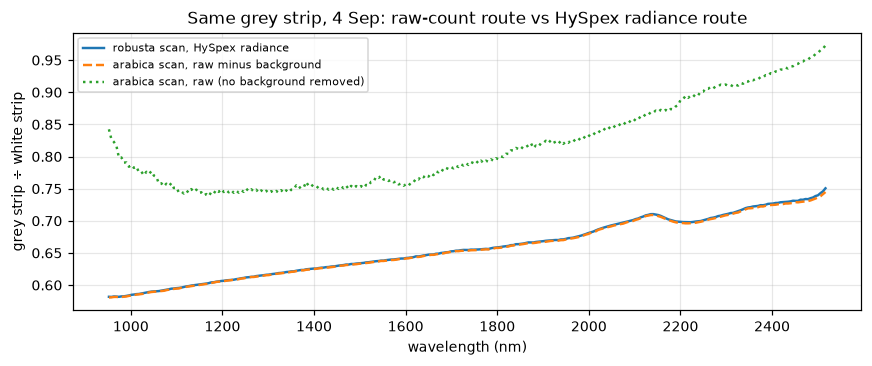

In [3]:
def strip_ratio(arr_rows, sub):
    # median over rows, then per-column ratio grey / white, median over the central columns
    W = np.median(arr_rows["white"] - sub, axis=0)
    G = np.median(arr_rows["grey"] - sub, axis=0)
    ok = W > (50 if np.nanmax(W) > 100 else 0)
    r = np.where(ok, G / np.where(ok, W, 1), np.nan)
    return np.nanmedian(r[20:364], axis=0)

ark = next(k for k in CUBES if "2026-09-04" in k and INFO[k]["capture"] == 1)
ac = CUBES[ark]
grab = lambda arr: {"white": np.array(arr[140:240], np.float64), "grey": np.array(arr[20:100], np.float64)}
a_rows = grab(ac.arr)
check = {"arabica scan, raw minus background": strip_ratio(a_rows, ac.bg.astype(np.float64)),
         "arabica scan, raw (no background removed)": strip_ratio(a_rows, 0.0)}
if CHECK_RAD.exists():
    rc = Cube(CHECK_RAD.with_suffix(".hdr"))
    check = {"robusta scan, HySpex radiance": strip_ratio(grab(rc.arr), 0.0), **check}
    ref = check["robusta scan, HySpex radiance"]
    band = (WL >= 1000) & (WL <= 2450)
    for k, v in check.items():
        if k.startswith("arabica"):
            q = v[band] / ref[band]
            print(f"{k:45s} ÷ radiance-based: median {np.median(q):.4f}  (1-99 %: {np.percentile(q,1):.4f}-{np.percentile(q,99):.4f})")
else:
    print("robusta radiance scan not found; check skipped")

fig, ax = plt.subplots(figsize=(8, 3.4))
for (k, v), ls in zip(check.items(), ["-", "--", ":"]):
    ax.plot(WL, v, ls, lw=1.6, label=k)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("grey strip ÷ white strip"); ax.grid(alpha=.3)
ax.set_title("Same grey strip, 4 Sep: raw-count route vs HySpex radiance route")
ax.legend(fontsize=7); plt.tight_layout()
plt.savefig(OUT / "check_raw_vs_radiance.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Composition labels

In [4]:
def parse_label(lab):
    if lab == "AR100":
        return dict(species="arabica", arabica_pct=100.0, robusta_pct=0.0, chicory_pct=0.0, unknown=False)
    m = re.match(r"AR\[(\d+):(\d+)\]", lab)
    if m:
        a, r = float(m.group(1)), float(m.group(2))
        assert a + r == 100, lab
        return dict(species="arabica_robusta", arabica_pct=a, robusta_pct=r, chicory_pct=0.0, unknown=False)
    return dict(species="unknown", arabica_pct=np.nan, robusta_pct=np.nan, chicory_pct=np.nan, unknown=True)

seen = []
for _, d, pl in DAY_RULES:
    if (d, pl) not in seen:
        seen.append((d, pl))
print(pd.DataFrame([dict(session=d, position_from_strip=i + 1, label=l, **parse_label(l))
                    for d, pl in seen for i, l in enumerate(pl)]).to_string(index=False))

 session  position_from_strip     label         species  arabica_pct  robusta_pct  chicory_pct  unknown
       1                    1         J         unknown          NaN          NaN          NaN     True
       1                    2         K         unknown          NaN          NaN          NaN     True
       1                    3         L         unknown          NaN          NaN          NaN     True
       1                    4 AR[50:50] arabica_robusta         50.0         50.0          0.0    False
       1                    5 AR[60:40] arabica_robusta         60.0         40.0          0.0    False
       1                    6 AR[70:30] arabica_robusta         70.0         30.0          0.0    False
       2                    1 AR[80:20] arabica_robusta         80.0         20.0          0.0    False
       2                    2 AR[90:10] arabica_robusta         90.0         10.0          0.0    False
       2                    3 AR[50:50] arabica_robusta         

## 5. White strip and dishes

**Automatic shapes.** The white strip is the longest run of bright rows in the top 450 rows; the rectangle
spans the full swath width and stops `STRIP_INSET_PX` rows short of each edge, so the grey strip above and
the shadow line below stay out. Each dish is found by its dark rim: a template that is bright inside a
circle and dark in a ring around it is slid over the image at radii 88–115 px, and the five strongest,
well-separated matches are the dishes, numbered from the strip downwards. The dish shape is that circle
shrunk by `DISH_INSET_PX`, which matches the size of the robusta ovals drawn by hand (about 100 px). The
mask cleaning in section 6 then removes any rim, shadow or glare that is still inside.

The shapes are saved in `rois.json` in the same format as the robusta `rois.json`, so the hand-drawing
window can open and adjust them (section 5b).

In [5]:
def find_strip(br):
    prof = np.nanmedian(br[:, 20:min(364, br.shape[1])], axis=1); top = prof[:450]
    thr = 0.5 * (np.percentile(top, 95) + np.percentile(top, 40)); hi = top > thr
    lab, n = ndimage.label(hi); k = np.argmax(ndimage.sum(hi, lab, range(1, n + 1))) + 1
    rows = np.where(lab == k)[0]
    return int(rows.min()), int(rows.max())

def ring_kernel(r_in, r_rim0, r_rim1):
    R = r_rim1 + 1; y, x = np.mgrid[-R:R + 1, -R:R + 1]; d = np.hypot(x, y)
    k = np.zeros_like(d); a = d <= r_in; b = (d >= r_rim0) & (d <= r_rim1)
    k[a] = 1 / a.sum(); k[b] = -1 / b.sum(); return k

def find_dishes(br, below, n, radii=range(88, 116, 3), min_sep=230):
    img = np.nan_to_num(br.astype(np.float64)); img = img / np.percentile(img[below:], 99)
    img[:below] = np.median(img[below:])
    best = rbest = None
    for r in radii:
        resp = signal.fftconvolve(img, ring_kernel(r - 8, r + 2, r + 12), mode="same")
        if best is None: best, rbest = resp, np.full(resp.shape, r)
        else:
            m = resp > best; best = np.where(m, resp, best); rbest = np.where(m, r, rbest)
    resp = best.copy(); resp[:below + 60] = -np.inf
    yy, xx = np.ogrid[:resp.shape[0], :resp.shape[1]]
    out = []
    for _ in range(n):
        cy, cx = np.unravel_index(np.argmax(resp), resp.shape)
        out.append(dict(cx=float(cx), cy=float(cy), r=int(rbest[cy, cx]), score=float(resp[cy, cx])))
        resp[(yy - cy) ** 2 + (xx - cx) ** 2 < min_sep ** 2] = -np.inf
    return sorted(out, key=lambda d: d["cy"])

def auto_rois(key):
    cube = CUBES[key]; br = cube.brightness(step=1); S = cube.shape[1]
    s0, s1 = find_strip(br)
    shapes = {"WHITE": dict(kind="rect", cx=(S - 1) / 2, cy=(s0 + s1) / 2,
                            ax=(S - 1) / 2 - 1, ay=(s1 - s0) / 2 - STRIP_INSET_PX, angle=0.0)}
    dishes = find_dishes(br, s1 + 12, len(INFO[key]["plates"]))
    for lab, d in zip(INFO[key]["plates"], dishes):
        rr = d["r"] - DISH_INSET_PX
        shapes[lab] = dict(kind="ellipse", cx=d["cx"], cy=d["cy"], ax=float(rr), ay=float(rr), angle=0.0)
    return shapes, (s0, s1), dishes

ALL_ROIS = json.loads(ROI_FILE.read_text()) if ROI_FILE.exists() else {}
REDETECT = []        # scan names to detect again even though rois.json already has them
for key in CUBES:
    if key in ALL_ROIS and key not in REDETECT:
        print(f"{key[:45]}: shapes from rois.json"); continue
    shapes, (s0, s1), dishes = auto_rois(key)
    ALL_ROIS[key] = shapes
    print(f"{key[:45]}: strip rows {s0}-{s1}; dish centres (col,row,radius) "
          + ", ".join(f"({d['cx']:.0f},{d['cy']:.0f},{d['r']})" for d in dishes))
ROI_FILE.write_text(json.dumps(ALL_ROIS, indent=1))
print("saved", ROI_FILE)

batch1stir1_SWIR_384_SN3189_9000us_2026-09-07: strip rows 120-249; dish centres (col,row,radius) (198,422,106), (148,713,109), (177,999,115), (114,1269,115), (170,1533,115)


batch1stir2_SWIR_384_SN3189_9000us_2026-09-07: strip rows 121-250; dish centres (col,row,radius) (203,431,106), (157,698,109), (182,966,109), (139,1243,109), (169,1509,112)


batch1stir3_SWIR_384_SN3189_9000us_2026-09-07: strip rows 121-250; dish centres (col,row,radius) (180,427,106), (158,699,106), (179,963,109), (138,1246,109), (166,1507,109)
stir1_SWIR_384_SN3189_9000us_2026-09-04T11561: shapes from rois.json
stir1_SWIR_384_SN3189_9000us_2026-09-04T13273: shapes from rois.json
stir2_SWIR_384_SN3189_9000us_2026-09-04T12065: shapes from rois.json
stir2_SWIR_384_SN3189_9000us_2026-09-04T13385: shapes from rois.json
stir3_SWIR_384_SN3189_9000us_2026-09-04T12154: shapes from rois.json
stir3_SWIR_384_SN3189_9000us_2026-09-04T13453: shapes from rois.json
saved /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_robusta_out/rois.json


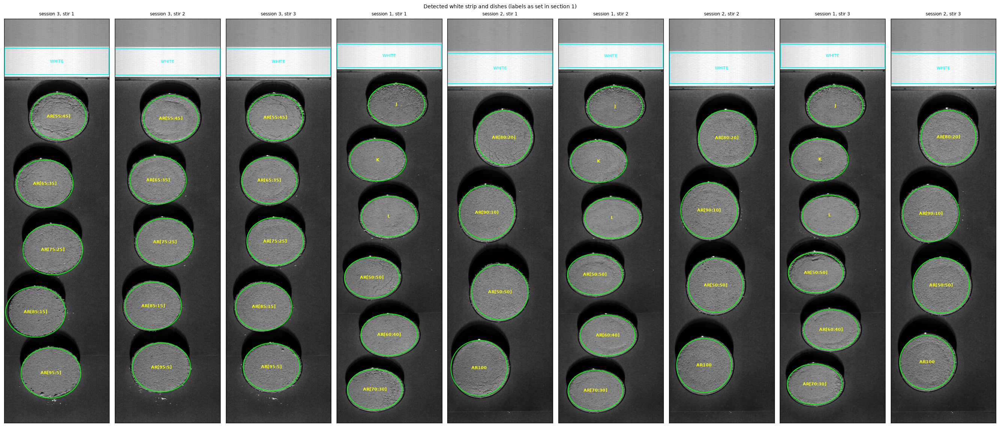

In [6]:
keys = list(CUBES)
fig, axs = plt.subplots(1, len(keys), figsize=(2.7 * len(keys), 10.5))
for ax, key in zip(np.atleast_1d(axs), keys):
    br = CUBES[key].brightness(step=1)
    ax.imshow(br, cmap="gray", aspect="auto", vmin=np.nanpercentile(br, 1), vmax=np.nanpercentile(br, 99.5))
    for lab, s in ALL_ROIS[key].items():
        if s["kind"] == "rect":
            ax.add_patch(Rectangle((s["cx"] - s["ax"], s["cy"] - s["ay"]), 2 * s["ax"], 2 * s["ay"],
                                   fill=False, ec="cyan", lw=1.3))
            ax.text(s["cx"], s["cy"], "WHITE", color="cyan", ha="center", va="center", fontsize=7)
        else:
            ax.add_patch(Ellipse((s["cx"], s["cy"]), 2 * s["ax"], 2 * s["ay"], angle=s.get("angle", 0),
                                 fill=False, ec="lime", lw=1.2))
            ax.text(s["cx"], s["cy"], lab, color="yellow", ha="center", va="center", fontsize=7,
                    fontweight="bold")
    ax.set_title(f"session {INFO[key]['day']}, stir {INFO[key]['capture']}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Detected white strip and dishes (labels as set in section 1)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "rois_overview.png", dpi=110, bbox_inches="tight"); plt.show()

### 5b. Adjusting a shape by hand (optional)

Set `EDIT_BY_HAND = True` in section 1 and list the scans in `REDRAW`. The same window as in the robusta
notebook opens with the automatic shapes loaded: right-drag moves the current shape, `W A S D` resizes,
`n`/`p` switch dish, `ENTER` saves. Needs `opencv-python` (not the headless build).

In [7]:
def screen_size(default=(1600, 900)):
    try:
        import tkinter as tk
        r = tk.Tk(); r.withdraw()
        s = (r.winfo_screenwidth(), r.winfo_screenheight()); r.destroy()
        return s
    except Exception:
        return default

def _u8(img, lo=1.5, hi=99.0):
    a = np.nan_to_num(img.astype(np.float32))
    l, h = np.percentile(a, [lo, hi])
    return np.clip((a-l)/max(h-l, 1e-9)*255, 0, 255).astype(np.uint8)

def ellipse_on_screen(s, sx, sy):
    th = np.deg2rad(s.get("angle", 0.0))
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    A = R @ np.diag([1/max(s["ax"],1e-6)**2, 1/max(s["ay"],1e-6)**2]) @ R.T
    Si = np.diag([1/max(sx,1e-9), 1/max(sy,1e-9)])
    w, V = np.linalg.eigh(Si @ A @ Si)
    w = np.maximum(w, 1e-12)
    return (float(1/np.sqrt(w[0])), float(1/np.sqrt(w[1]))), float(np.degrees(np.arctan2(V[1,0], V[0,0])))

def draw_rois(cube, key, plate_labels, existing=None):
    SCREEN_W, SCREEN_H = screen_size(); VIEW_W, VIEW_H = int(SCREEN_W*0.86), int(SCREEN_H*0.80)
    base = _u8(cube.brightness(step=1)); H, W = base.shape
    FIT = (VIEW_W/W, VIEW_H/H); ONE = (max(1.0, VIEW_W/W),) * 2
    labels = ["WHITE"] + list(plate_labels)
    shapes = {k: dict(v) for k, v in (existing or {}).items()}
    st = dict(i=0, mode="fit", top=0, move=None, save=False)
    def sxsy(): return FIT if st["mode"] == "fit" else ONE
    def d2o(x, y): sx, sy = sxsy(); return x/sx, (y + st["top"])/sy
    def o2d(x, y): sx, sy = sxsy(); return x*sx, y*sy - st["top"]
    def render():
        sx, sy = sxsy()
        big = cv2.cvtColor(cv2.resize(base, (max(1,int(W*sx)), max(1,int(H*sy))),
                                      interpolation=cv2.INTER_AREA), cv2.COLOR_GRAY2BGR)
        ph = big.shape[0] if st["mode"] == "fit" else min(VIEW_H, big.shape[0])
        st["top"] = int(np.clip(st["top"], 0, max(0, big.shape[0]-ph)))
        view = big[st["top"]:st["top"]+ph].copy(); cur = labels[st["i"]]
        for lab, s in shapes.items():
            col = (0,0,255) if lab == cur else ((0,220,255) if s["kind"] == "rect" else (0,230,0))
            cx, cy = o2d(s["cx"], s["cy"])
            if s["kind"] == "ellipse":
                axes, ang = ellipse_on_screen(s, sx, sy)
                cv2.ellipse(view, (int(cx),int(cy)), (max(1,int(axes[0])), max(1,int(axes[1]))), ang, 0, 360, col, 2)
            else:
                cv2.rectangle(view, (int(cx-s["ax"]*sx),int(cy-s["ay"]*sy)), (int(cx+s["ax"]*sx),int(cy+s["ay"]*sy)), col, 2)
            cv2.putText(view, lab, (int(cx), int(cy)), cv2.FONT_HERSHEY_SIMPLEX, .45, col, 1, cv2.LINE_AA)
        cv2.putText(view, f"[{st['i']+1}/{len(labels)}] {cur}", (8,17), cv2.FONT_HERSHEY_SIMPLEX, .5, (255,255,255), 1)
        cv2.imshow(key, view)
    def on_mouse(ev, x, y, flags, _):
        ox, oy = d2o(x, y); cur = labels[st["i"]]
        if ev == cv2.EVENT_RBUTTONDOWN: st["move"] = (ox, oy)
        elif ev == cv2.EVENT_RBUTTONUP: st["move"] = None
        elif ev == cv2.EVENT_MOUSEMOVE and st["move"] and cur in shapes:
            shapes[cur]["cx"] += ox-st["move"][0]; shapes[cur]["cy"] += oy-st["move"][1]
            st["move"] = (ox, oy); render()
    cv2.namedWindow(key, cv2.WINDOW_NORMAL); cv2.resizeWindow(key, VIEW_W, VIEW_H)
    cv2.setMouseCallback(key, on_mouse); render()
    while True:
        k = cv2.waitKey(20) & 0xFF
        if k == 255: continue
        s = shapes.get(labels[st["i"]])
        if k == 13: st["save"] = True; break
        elif k in (27, ord("q")): break
        elif k == ord("n"): st["i"] = (st["i"]+1) % len(labels)
        elif k == ord("p"): st["i"] = (st["i"]-1) % len(labels)
        elif k == ord("1"): st["mode"] = "fit"; st["top"] = 0
        elif k == ord("2"): st["mode"] = "one"; st["top"] = int(max(0, (s["cy"] if s else 0)*ONE[1] - VIEW_H/2))
        elif k == ord("j"): st["top"] += VIEW_H//2
        elif k == ord("k"): st["top"] -= VIEW_H//2
        elif s:
            if   k == ord("w"): s["cy"] -= 1
            elif k == ord("s"): s["cy"] += 1
            elif k == ord("a"): s["cx"] -= 1
            elif k == ord("d"): s["cx"] += 1
            elif k == ord("W"): s["ay"] += 1
            elif k == ord("S"): s["ay"] = max(2, s["ay"]-1)
            elif k == ord("D"): s["ax"] += 1
            elif k == ord("A"): s["ax"] = max(2, s["ax"]-1)
        render()
    cv2.destroyWindow(key)
    for _ in range(5): cv2.waitKey(1)
    return shapes if st["save"] else None

REDRAW = []          # e.g. ["stir1_SWIR_384_SN3189_9000us_2026-09-04T151627_raw"]
if EDIT_BY_HAND:
    for key in REDRAW:
        res = draw_rois(CUBES[key], key, INFO[key]["plates"], existing=ALL_ROIS.get(key))
        if res:
            ALL_ROIS[key] = res; ROI_FILE.write_text(json.dumps(ALL_ROIS, indent=1)); print("saved", key)
else:
    print("hand editing off -- using the automatic shapes")

hand editing off -- using the automatic shapes


## 6. White reference and dish masks

Same as the robusta notebook. The white reference is the median of the strip rows **per across-track
column**, so the lamp and lens profile across the swath is measured rather than assumed. One addition for
raw counts: a few single detector pixels (one band in one column) respond far below their neighbours. They
are found on the white strip and set to missing, so a patch averages the other columns for that band.

Inside each dish shape: pixels below 55 % of the dish median (rim, shadow) and above the 99.7th percentile,
dilated by 1 px (glare), are removed, and the shape is eroded by `ERODE_PX`.

In [8]:
def shape_mask(shape, H, W):
    m = np.zeros((H, W), np.uint8)
    if shape["kind"] == "poly":
        cv2.fillPoly(m, [np.array([[int(round(a)), int(round(b))] for a, b in shape["pts"]], np.int32)], 1)
        return m.astype(bool)
    cx, cy = int(round(shape["cx"])), int(round(shape["cy"]))
    ax, ay = int(round(shape["ax"])), int(round(shape["ay"]))
    if shape["kind"] == "ellipse":
        cv2.ellipse(m, (cx, cy), (max(ax,1), max(ay,1)), shape.get("angle", 0), 0, 360, 1, -1)
    else:
        cv2.rectangle(m, (cx-ax, cy-ay), (cx+ax, cy+ay), 1, -1)
    return m.astype(bool)


def clean_mask(mask, bright, kind="ellipse", erode=ERODE_PX, dark_frac=0.55, spec_q=99.7):
    m = mask.astype(np.uint8)
    e = 0 if kind == "poly" else erode
    if e > 0:
        m = cv2.erode(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*e+1, 2*e+1)))
    m = m.astype(bool)
    if m.sum() < 30: return m
    m &= bright > dark_frac * np.nanmedian(bright[m])
    if m.sum() > 50:
        hi = np.nanpercentile(bright[m], spec_q)
        m &= ~cv2.dilate((bright > hi).astype(np.uint8), np.ones((3,3), np.uint8)).astype(bool)
    return m


def build_white(cube, shape, bad_frac=0.5, pix_tol=0.5):
    r0, r1 = int(shape["cy"] - shape["ay"]), int(shape["cy"] + shape["ay"])
    c0, c1 = int(shape["cx"] - shape["ax"]), int(shape["cx"] + shape["ax"])
    r0, c0 = max(0, r0), max(0, c0)
    r1, c1 = min(cube.shape[0], r1), min(cube.shape[1], c1)
    S = cube.shape[1]
    W = np.full((S, cube.wl.size), np.nan)
    W[c0:c1] = np.nanmedian(cube.region(r0, r1, c0, c1), axis=0)
    # whole columns far below the rest are repaired from their neighbours (as for robusta)
    ref = np.nanmedian(W[c0:c1], axis=0)
    lvl = np.nanmedian(W / np.maximum(ref, 1e-9), axis=1)
    bad = ~np.isfinite(lvl) | (lvl < bad_frac)
    good = np.where(~bad)[0]
    if bad.any() and good.size > 2:
        for jb in range(W.shape[1]):
            W[bad, jb] = np.interp(np.where(bad)[0], good, W[good, jb])
    # single detector pixels (column, band) that disagree with their column neighbours
    local = ndimage.median_filter(np.nan_to_num(W), size=(9, 1), mode="nearest")
    badpix = ~np.isfinite(W) | (W <= 0) | (np.abs(W / np.maximum(local, 1e-9) - 1) > pix_tol)
    return W, badpix, (r0, r1, c0, c1), int(bad.sum()), (c1 - c0) / S


WHITE, BADPIX, MASKS = {}, {}, {}
for key in ALL_ROIS:
    cube = CUBES[key]; H, Wd = cube.shape[0], cube.shape[1]
    Wc, bp, wbox, nbad, cov = build_white(cube, ALL_ROIS[key]["WHITE"])
    WHITE[key], BADPIX[key] = Wc, bp
    print(f"{key[:45]}: white rows {wbox[0]}-{wbox[1]}, spans {cov*100:.0f}% of the swath, "
          f"{nbad} columns repaired, {bp.sum()} single bad detector pixels")
    br = cube.brightness(step=1)
    mk = {}
    for lab in INFO[key]["plates"]:
        sh = ALL_ROIS[key][lab]
        raw = shape_mask(sh, H, Wd)
        cl = clean_mask(raw, br, kind=sh["kind"])
        mk[lab] = dict(raw=raw, mask=cl, n=int(cl.sum()), keep=float(cl.sum()/max(raw.sum(), 1)))
        print(f"    {lab:10s} {cl.sum():7d} px ({mk[lab]['keep']*100:.0f}% of the shape)")
    MASKS[key] = mk

/tmp/ipykernel_126431/4129208707.py:36: RuntimeWarning: All-NaN slice encountered
  W[c0:c1] = np.nanmedian(cube.region(r0, r1, c0, c1), axis=0)
/tmp/ipykernel_126431/4129208707.py:39: RuntimeWarning: All-NaN slice encountered
  lvl = np.nanmedian(W / np.maximum(ref, 1e-9), axis=1)


stir1_SWIR_384_SN3189_9000us_2026-09-04T11561: white rows 126-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    J            29496 px (88% of the shape)
    K            30399 px (90% of the shape)
    L            28495 px (90% of the shape)
    AR[50:50]    28523 px (90% of the shape)
    AR[60:40]    30336 px (90% of the shape)
    AR[70:30]    28277 px (89% of the shape)


stir1_SWIR_384_SN3189_9000us_2026-09-04T13273: white rows 127-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AR[80:20]    28410 px (90% of the shape)
    AR[90:10]    28412 px (90% of the shape)
    AR[50:50]    30238 px (90% of the shape)
    AR100        29928 px (89% of the shape)


stir2_SWIR_384_SN3189_9000us_2026-09-04T12065: white rows 127-241, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    J            27914 px (88% of the shape)
    K            30248 px (90% of the shape)
    L            28599 px (90% of the shape)
    AR[50:50]    28500 px (90% of the shape)
    AR[60:40]    28510 px (90% of the shape)
    AR[70:30]    28388 px (90% of the shape)


stir2_SWIR_384_SN3189_9000us_2026-09-04T13385: white rows 126-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AR[80:20]    30284 px (90% of the shape)
    AR[90:10]    30218 px (90% of the shape)
    AR[50:50]    28344 px (89% of the shape)
    AR100        28292 px (89% of the shape)


stir3_SWIR_384_SN3189_9000us_2026-09-04T12154: white rows 126-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    J            28170 px (89% of the shape)
    K            30254 px (90% of the shape)
    L            28375 px (90% of the shape)
    AR[50:50]    27242 px (86% of the shape)
    AR[60:40]    28495 px (90% of the shape)
    AR[70:30]    28290 px (89% of the shape)


stir3_SWIR_384_SN3189_9000us_2026-09-04T13453: white rows 127-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AR[80:20]    28460 px (90% of the shape)
    AR[90:10]    30296 px (90% of the shape)
    AR[50:50]    30184 px (90% of the shape)
    AR100        28332 px (89% of the shape)


batch1stir1_SWIR_384_SN3189_9000us_2026-09-07: white rows 128-241, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AR[55:45]    27736 px (88% of the shape)
    AR[65:35]    30178 px (90% of the shape)
    AR[75:25]    34021 px (90% of the shape)
    AR[85:15]    32898 px (87% of the shape)
    AR[95:5]     34113 px (91% of the shape)


batch1stir2_SWIR_384_SN3189_9000us_2026-09-07: white rows 129-242, spans 99% of the swath, 3 columns repaired, 10 single bad detector pixels
    AR[55:45]    28650 px (90% of the shape)
    AR[65:35]    30330 px (90% of the shape)
    AR[75:25]    30346 px (90% of the shape)
    AR[85:15]    30332 px (90% of the shape)
    AR[95:5]     32091 px (90% of the shape)


batch1stir3_SWIR_384_SN3189_9000us_2026-09-07: white rows 129-242, spans 99% of the swath, 3 columns repaired, 10 single bad detector pixels
    AR[55:45]    28268 px (89% of the shape)
    AR[65:35]    28443 px (90% of the shape)
    AR[75:25]    30298 px (90% of the shape)
    AR[85:15]    30258 px (90% of the shape)
    AR[95:5]     30193 px (90% of the shape)


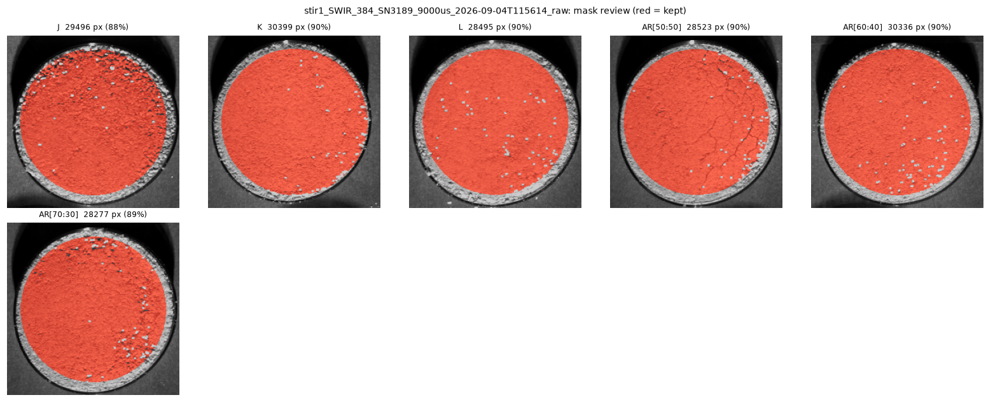

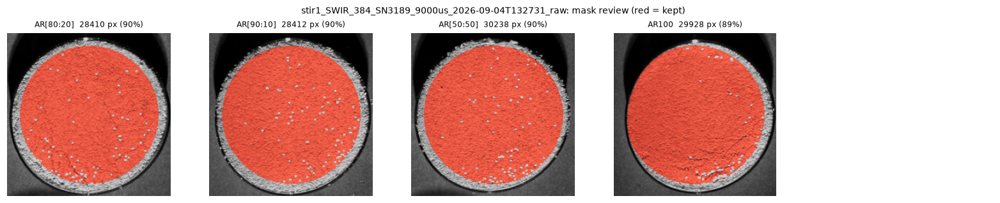

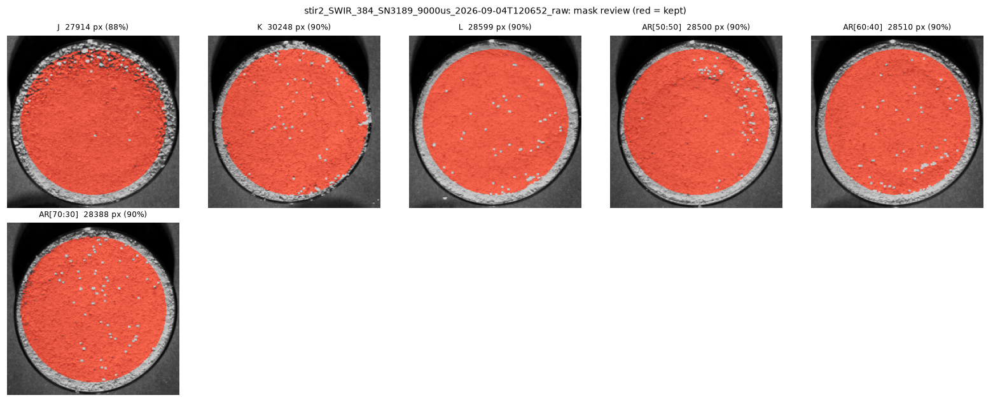

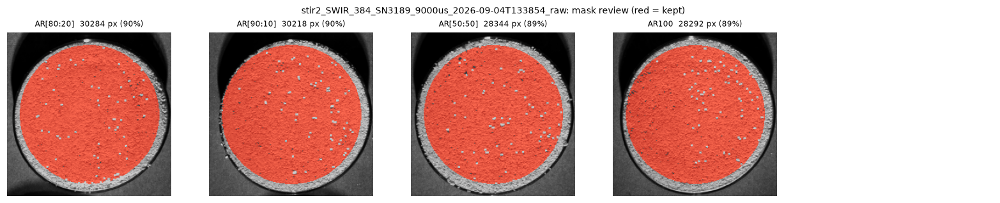

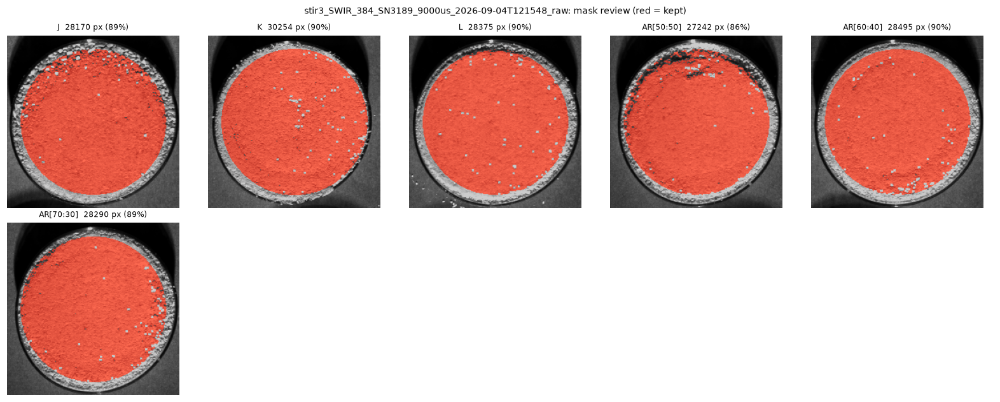

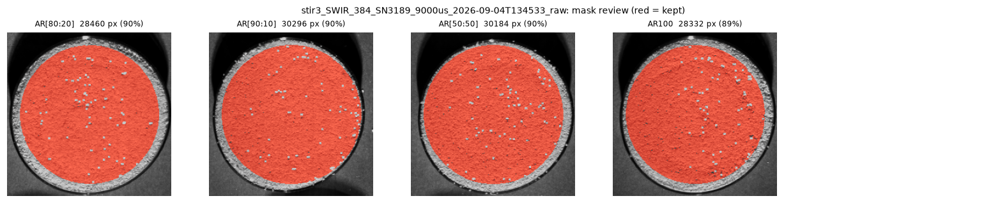

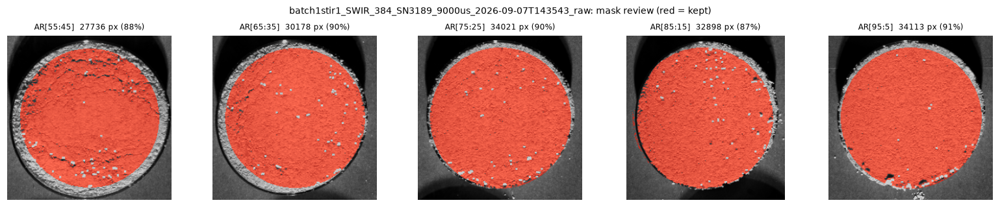

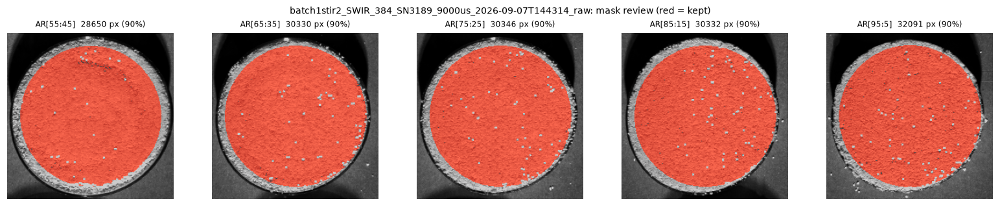

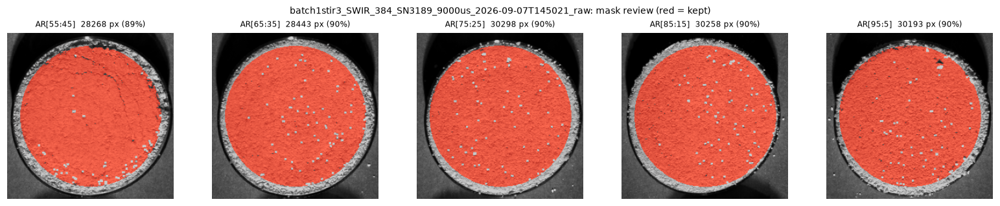

In [9]:
def review(key, cols=5):
    br = CUBES[key].brightness(step=1)
    items = list(MASKS[key].items())
    rows = int(np.ceil(len(items)/cols))
    fig, axs = plt.subplots(rows, cols, figsize=(2.9*cols, 2.9*rows), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    for jx, (lab, d) in enumerate(items):
        r, c = divmod(jx, cols); ax = axs[r][c]
        ys, xs = np.where(d["raw"])
        p = 14
        r0, r1 = max(0, ys.min()-p), min(br.shape[0], ys.max()+p)
        c0, c1 = max(0, xs.min()-p), min(br.shape[1], xs.max()+p)
        sub = np.nan_to_num(br[r0:r1, c0:c1])
        lo, hi = np.nanpercentile(sub, [2, 98])
        g = np.clip((sub-lo)/max(hi-lo, 1e-9), 0, 1)
        rgb = np.dstack([g, g, g]); mm = d["mask"][r0:r1, c0:c1]
        rgb[...,0] = np.where(mm, np.clip(g*.5+.5, 0, 1), g*.8)
        rgb[...,1] = np.where(mm, g*.42, g*.8)
        rgb[...,2] = np.where(mm, g*.32, g*.8)
        ax.imshow(np.clip(rgb, 0, 1)); ax.axis("off")
        ax.set_title(f"{lab}  {d['n']} px ({d['keep']*100:.0f}%)", fontsize=8)
    fig.suptitle(f"{key}: mask review (red = kept)", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / f"{key}_masks.png", dpi=125, bbox_inches="tight"); plt.show()

for key in MASKS: review(key)

## 7. Reflectance and patch sampling

    R(row, col, band) = [raw(row, col, band) − background(col, band)] / white(col, band) × R_certified(band)

where `white` is the background-subtracted white strip from section 6. Applied inside each dish mask only.
Patches: 12 × 12 px on a non-overlapping grid, kept if ≥ 92 % of their pixels are in the mask, at most
150 per dish (random subsample, seed 0), each averaged into one spectrum.

In [10]:
def plate_reflectance(key, lab):
    cube = CUBES[key]; d = MASKS[key][lab]
    ys, xs = np.where(d["mask"])
    if ys.size == 0: return None
    r0, r1, c0, c1 = ys.min(), ys.max()+1, xs.min(), xs.max()+1
    L = cube.region(r0, r1, c0, c1)
    W = WHITE[key][c0:c1, :][None, :, :]
    R = L / np.maximum(W, 1e-9) * R_WHITE[None, None, :]
    R[np.broadcast_to(BADPIX[key][None, c0:c1, :], R.shape)] = np.nan
    R[(R < -0.05) | (R > 1.6)] = np.nan
    return R, d["mask"][r0:r1, c0:c1], (int(r0), int(c0))


def sample_patches(R, m, patch=PATCH, stride=STRIDE, min_valid=MIN_VALID, max_n=MAX_PER_PLATE, rng=RNG):
    H, Wd, B = R.shape
    specs, pos = [], []
    for i in range(0, H-patch+1, stride):
        for jx in range(0, Wd-patch+1, stride):
            sm = m[i:i+patch, jx:jx+patch]
            if sm.mean() < min_valid: continue
            s = np.nanmean(R[i:i+patch, jx:jx+patch, :][sm], axis=0)
            if np.all(np.isfinite(s)):
                specs.append(s); pos.append((i+patch//2, jx+patch//2, int(sm.sum())))
    if not specs: return np.empty((0, R.shape[2])), []
    if max_n and len(specs) > max_n:
        keep = np.sort(rng.choice(len(specs), max_n, replace=False))
        specs = [specs[k] for k in keep]; pos = [pos[k] for k in keep]
    return np.array(specs), pos


X, rows = [], []
for key in MASKS:
    for lab in INFO[key]["plates"]:
        res = plate_reflectance(key, lab)
        if res is None: continue
        R, m, (r0, c0) = res
        specs, pos = sample_patches(R, m)
        if specs.shape[0] == 0:
            print(f"{key} {lab}: no valid patches"); continue
        X.append(specs)
        info = parse_label(lab)
        for si, (pr, pc, npx) in enumerate(pos):
            rows.append(dict(sample_id=f"{key}|{lab}|{si:04d}", scan=key, day=INFO[key]["day"],
                             capture=INFO[key]["capture"], label=lab, **info,
                             group=f"{key}|{lab}", plate=f"day{INFO[key]['day']}|{lab}",
                             patch_row=r0+pr, patch_col=c0+pc, n_pixels=npx))
        print(f"{key[:40]:40s} {lab:10s} {int(m.sum()):6d} px -> {specs.shape[0]:4d} patches")

X = np.vstack(X); META = pd.DataFrame(rows)
print(f"\n{X.shape[0]} patches x {X.shape[1]} bands from {META['scan'].nunique()} scans, "
      f"{META['group'].nunique()} dishes")
print(META.groupby(["day", "capture"]).size().rename("patches").to_string())
print(f"patch = {PATCH}x{PATCH} px ~ {PATCH*MM_PER_PX:.1f} x {PATCH*MM_PER_PX:.1f} mm")

stir1_SWIR_384_SN3189_9000us_2026-09-04T J           29496 px ->  150 patches


stir1_SWIR_384_SN3189_9000us_2026-09-04T K           30399 px ->  150 patches


stir1_SWIR_384_SN3189_9000us_2026-09-04T L           28495 px ->  150 patches


stir1_SWIR_384_SN3189_9000us_2026-09-04T AR[50:50]   28523 px ->  150 patches


stir1_SWIR_384_SN3189_9000us_2026-09-04T AR[60:40]   30336 px ->  150 patches


stir1_SWIR_384_SN3189_9000us_2026-09-04T AR[70:30]   28277 px ->  150 patches


... (35 outputs left out)

batch1stir3_SWIR_384_SN3189_9000us_2026- AR[65:35]   28443 px ->  150 patches


batch1stir3_SWIR_384_SN3189_9000us_2026- AR[75:25]   30298 px ->  150 patches


batch1stir3_SWIR_384_SN3189_9000us_2026- AR[85:15]   30258 px ->  150 patches


batch1stir3_SWIR_384_SN3189_9000us_2026- AR[95:5]    30193 px ->  150 patches

6740 patches x 288 bands from 9 scans, 45 dishes
day  capture
1    1          900
     2          900
     3          900
2    1          600
     2          600
     3          600
3    1          740
     2          750
     3          750
patch = 12x12 px ~ 8.8 x 8.8 mm


## 8. Roles and splits

Same columns as before, with **robusta %** as the target: every AR blend and AR 100 is `calibration`
(0–50 % robusta), J, K and L are `unknown`.

In [11]:
TARGET, CAL_MAX, HOLDOUT_LEVEL, N_PLATE_FOLDS = "robusta_pct", 50.0, 30.0, 5

def add_splits(meta):
    meta = meta.copy()
    meta["role"] = np.where(meta["unknown"], "unknown",
                   np.where(meta[TARGET] <= CAL_MAX, "calibration", "extrapolation_check"))
    cal = meta["role"] == "calibration"
    lmap = {v: i for i, v in enumerate(sorted(meta.loc[cal, TARGET].unique()))}
    gmap = {g: i % N_PLATE_FOLDS for i, g in enumerate(sorted(meta.loc[cal, "group"].unique()))}
    for col, val in [("fold_level", meta.loc[cal, TARGET].map(lmap)),
                     ("fold_plate", meta.loc[cal, "group"].map(gmap)),
                     ("fold_capture", meta.loc[cal, "capture"])]:
        meta[col] = pd.NA; meta.loc[cal, col] = val; meta[col] = meta[col].astype("Int64")
    meta["split_holdout"] = np.where(~cal, "excluded", np.where(meta[TARGET] == HOLDOUT_LEVEL, "test", "train"))
    return meta

META = add_splits(META)
print(META.groupby(["day", "label", "role"]).agg(robusta=(TARGET, "first"),
      dishes=("group", "nunique"), patches=("sample_id", "size")).to_string())

                           robusta  dishes  patches
day label     role                                 
1   AR[50:50] calibration     50.0       3      450
    AR[60:40] calibration     40.0       3      450
    AR[70:30] calibration     30.0       3      450
    J         unknown          NaN       3      450
    K         unknown          NaN       3      450
    L         unknown          NaN       3      450
2   AR100     calibration      0.0       3      450
    AR[50:50] calibration     50.0       3      450
    AR[80:20] calibration     20.0       3      450
    AR[90:10] calibration     10.0       3      450
3   AR[55:45] calibration     45.0       3      440
    AR[65:35] calibration     35.0       3      450
    AR[75:25] calibration     25.0       3      450
    AR[85:15] calibration     15.0       3      450
    AR[95:5]  calibration      5.0       3      450


## 9. The CSV

`training_samples.csv`: one row per patch, the same columns as the other extractions plus `robusta_pct`.

In [12]:
wl_cols = [str(w) for w in WL_R]
META_COLS = ["sample_id", "scan", "day", "capture", "label", "plate", "species",
             "arabica_pct", "robusta_pct", "chicory_pct", "unknown", "role", "group",
             "fold_level", "fold_plate", "fold_capture", "split_holdout",
             "patch_row", "patch_col", "n_pixels"]
df = pd.concat([META[META_COLS].reset_index(drop=True), pd.DataFrame(np.round(X, 6), columns=wl_cols)], axis=1)
df.to_csv(OUT / "training_samples.csv", index=False)
pd.DataFrame({"band": np.arange(1, WL.size+1), "wavelength_exact_nm": np.round(WL, 4),
              "wavelength_rounded_nm": WL_R, "white_certified": np.round(R_WHITE, 5),
              "beyond_certificate": OUTSIDE}).to_csv(OUT / "wavelengths.csv", index=False)
print(f"training_samples.csv: {df.shape[0]} rows x {df.shape[1]} columns")
print(df.groupby(["day", "role"]).agg(dishes=("group", "nunique"), patches=("sample_id", "size")).to_string())

s1 = pd.read_csv(S1_CSV)
ref_ab = s1[s1.label == "AB100"][wl_cols].to_numpy().mean(0)      # pure arabica, 1 Sep
ref_rb = s1[s1.label == "RB100"][wl_cols].to_numpy().mean(0)      # pure robusta, 1 Sep

training_samples.csv: 6740 rows x 308 columns
                 dishes  patches
day role                        
1   calibration       9     1350
    unknown           9     1350
2   calibration      12     1800
3   calibration      15     2240


## 10. First look, and checks of the labels

Left: mean spectrum of each blend. **Label check:** each dish's mean spectrum (absorbance + offset, 1000–2450 nm)
is placed on the line from pure arabica (AB100, 1 Sep) to pure robusta (RB100, 1 Sep): 0 = looks like pure arabica,
1 = looks like pure robusta. No blend labels are used. If the labels are right, the score rises with the labelled
robusta % in every scan, and **AR 100 sits near 0** (confirming it is pure arabica, not pure robusta). Absolute
values are not calibrated; only the order and the AR 100 end matter.

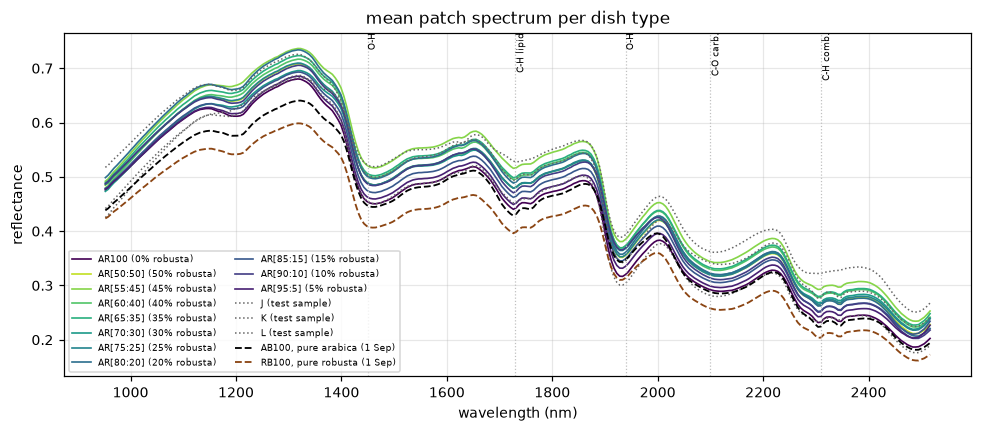

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
cmap = plt.get_cmap("viridis")
for lab, g in META[META.role == "calibration"].groupby("label"):
    pct = g[TARGET].iloc[0]
    ax.plot(WL, X[g.index].mean(0), lw=1.1, color=cmap(pct / 55), label=f"{lab} ({pct:.0f}% robusta)")
for lab, g in META[META.role == "unknown"].groupby("label"):
    ax.plot(WL, X[g.index].mean(0), lw=1, ls=":", color="0.4", label=f"{lab} (test sample)")
ax.plot(WL, ref_ab, "k--", lw=1.2, label="AB100, pure arabica (1 Sep)")
ax.plot(WL, ref_rb, ls="--", color="saddlebrown", lw=1.2, label="RB100, pure robusta (1 Sep)")
for nm, t in [(1450,"O-H"), (1730,"C-H lipid"), (1940,"O-H"), (2100,"C-O carb."), (2310,"C-H comb.")]:
    ax.axvline(nm, color="0.75", lw=.8, ls=":"); ax.text(nm, ax.get_ylim()[1], t, fontsize=6, rotation=90, va="top")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(alpha=.3); ax.legend(fontsize=6, ncol=2)
ax.set_title("mean patch spectrum per dish type")
plt.tight_layout(); plt.savefig(OUT / "samples_overview.png", dpi=130, bbox_inches="tight"); plt.show()

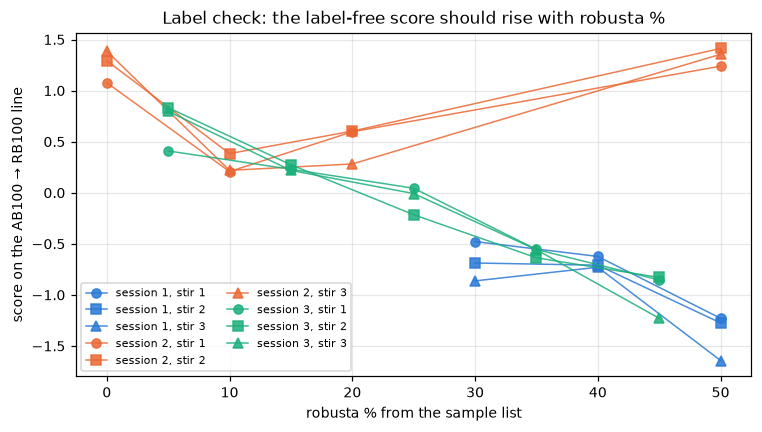

 session  stir  spearman                                           order_by_score
       3     1      -1.0 AR[95:5] > AR[85:15] > AR[75:25] > AR[65:35] > AR[55:45]
       3     2      -1.0 AR[95:5] > AR[85:15] > AR[75:25] > AR[65:35] > AR[55:45]
       3     3      -1.0 AR[95:5] > AR[85:15] > AR[75:25] > AR[65:35] > AR[55:45]
       1     1      -1.0                        AR[70:30] > AR[60:40] > AR[50:50]
       2     1       0.4                AR[50:50] > AR100 > AR[80:20] > AR[90:10]
       1     2      -1.0                        AR[70:30] > AR[60:40] > AR[50:50]
       2     2       0.4                AR[50:50] > AR100 > AR[80:20] > AR[90:10]
       1     3      -0.5                        AR[60:40] > AR[70:30] > AR[50:50]
       2     3      -0.2                AR100 > AR[50:50] > AR[80:20] > AR[90:10]

mean score per dish type (0 = pure arabica, 1 = pure robusta):
           robusta_pct  score  dishes
label                                
L                  NaN -3.638       3
AR

In [14]:
band = (WL >= 1000) & (WL <= 2450)
def prep(R):
    Z = np.log10(1.0 / np.clip(np.asarray(R, float), 1e-3, None))[..., band]
    return Z - Z.mean(-1, keepdims=True)
z_ab, z_rb = prep(ref_ab), prep(ref_rb); d = z_rb - z_ab
dish = (META.assign(i=np.arange(len(META))).groupby(["scan", "day", "capture", "label", "role"])
        .agg(robusta_pct=(TARGET, "first"), idx=("i", list)).reset_index())
dish["score"] = [float((prep(X[ix].mean(0)) - z_ab) @ d / (d @ d)) for ix in dish["idx"]]

from scipy.stats import spearmanr
cal = dish[dish.role == "calibration"]
fig, ax = plt.subplots(figsize=(7, 4))
for (day, cap), g in cal.groupby(["day", "capture"]):
    g = g.sort_values("robusta_pct")
    ax.plot(g.robusta_pct, g.score, marker="os^"[cap - 1], lw=1, color={1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}[day],
            alpha=.85, label=f"session {day}, stir {cap}")
ax.set_xlabel("robusta % from the sample list"); ax.set_ylabel("score on the AB100 → RB100 line")
ax.set_title("Label check: the label-free score should rise with robusta %"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "label_check.png", dpi=130, bbox_inches="tight"); plt.show()

rows = [dict(session=day, stir=cap, spearman=round(float(spearmanr(g.robusta_pct, g.score).statistic), 2),
             order_by_score=" > ".join(g.sort_values("score", ascending=False).label))
        for (scan, day, cap), g in cal.groupby(["scan", "day", "capture"])]
print(pd.DataFrame(rows).to_string(index=False))
print("\nmean score per dish type (0 = pure arabica, 1 = pure robusta):")
print(dish.groupby(["label"]).agg(robusta_pct=("robusta_pct", "first"), score=("score", "mean"), dishes=("score", "size"))
      .sort_values("score").round(3).to_string())
dish.drop(columns="idx").to_csv(OUT / "label_check.csv", index=False)

## 11. What this gives you

`arabica_robusta_out/training_samples.csv`: patches from the 4 Sep scans (session 1: AR 50/60/70 + test samples
J, K, L; session 2: AR 80/90/50 + AR 100), robusta 0, 10, 20, 30, 40, 50 %. When the 7 Sep scans are copied into
`RIYAN HDD/arabica+robusta/`, re-running this notebook adds session 3 (5–45 %) with no code changes.